# Next-RAM Prediction in Asteroids

> **Overview.** How well does an MLP learn online to predict the next Asteroids RAM state from the current one and the
> action, and how does that change with step size, width and depth?

**Setup.** Transitions from the 01 policy in mode 0, difficulty 0, learned once in time order (transitions across a
game-over reset are dropped). Input: the 1,024 RAM bits and a one-hot of the 14 actions. Output: one logit per bit of
the next RAM, trained with per-bit cross-entropy. Hidden layers use leaky ReLU. Adam, one update per transition, step
sizes 2⁻¹⁶ … 2⁻⁶. Each prediction is scored before its update, by its loss and by the fraction of bytes it gets exactly
right, counting only bytes whose next value has entropy above 0.6 nats (as in Veličković et al. 2021). The reference
copies the current RAM; for the loss, it gives each bit probability 1 − q of keeping its value, where q is the fraction
of bits that change. The milestone is the best Asteroids accuracy in Veličković et al. 2021, 80.7%, from a
message-passing network trained offline on a trained agent's data (copying got 70.7% on their data).
1. Step size: 1 hidden layer of 128 units, 5 seeds.
2. Width: 1 hidden layer of 32, 128, 512 or 2,048 units, 1 seed.
3. Depth: 1, 2 or 3 hidden layers of 128 units, 1 seed.

500k transitions are collected; `N_STEPS` sets how many are learned from.

In [35]:
import os
from functools import partial

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

from asteroids import collect

DATA = 'data_mode0_diff0.npz'
N_STEPS = 200_000  # transitions learned from
WINDOW = N_STEPS // 100  # steps per logged average
STEP_SIZES = 2.0 ** np.arange(-15, -7)

if not os.path.exists(DATA):
    np.savez_compressed(DATA, **collect(500_000, mode=0, difficulty=0, seed=0))
data = np.load(DATA)
valid = data['valid']
x, a, y = data['ram'][:-1][valid][:N_STEPS], data['action'][valid][:N_STEPS], data['ram'][1:][valid][:N_STEPS]

# Bytes counted in the accuracy, as in Veličković et al. 2021: those whose next value has entropy above 0.6 nats.
p = np.stack([np.bincount(byte, minlength=256) for byte in y.T]) / len(y)
varied = -(p * np.log(np.where(p > 0, p, 1))).sum(1) > 0.6
RMR_ACCURACY = 0.8069  # Veličković et al. 2021, Table 2, Asteroids, message-passing network

# Reference: copy the current RAM. For the loss, each bit keeps its value with probability 1 - q, where q is the
# fraction of bits that change. Both over the last 10% of steps.
last = slice(-N_STEPS // 10, None)
q = (np.unpackbits(x[last], axis=1) != np.unpackbits(y[last], axis=1)).mean()
copy_final = [-(q * np.log(q) + (1 - q) * np.log(1 - q)), (x[last][:, varied] == y[last][:, varied]).mean()]
x, a, y = jnp.asarray(x), jnp.asarray(a), jnp.asarray(y)

In [36]:
def init(key, width, depth):
    sizes = [1024 + 14] + [width] * depth + [1024]
    keys = jax.random.split(key, len(sizes) - 1)
    return [(jax.random.normal(k, (m, n)) / np.sqrt(m), jnp.zeros(n)) for k, m, n in zip(keys, sizes[:-1], sizes[1:])]


def forward(params, h):
    for w, b in params[:-1]:
        h = jax.nn.leaky_relu(h @ w + b)
    w, b = params[-1]
    return h @ w + b


def train(key, step_size, x, a, y, width, depth):
    # Learns online from the transitions in order; returns the loss and fraction of bytes exactly right, averaged over
    # each window, shape (2, n_windows).
    params = init(key, width, depth)
    opt = optax.adam(step_size)

    def step(carry, transition):
        params, opt_state = carry
        ram, action, next_ram = transition
        inputs = jnp.concatenate([jnp.unpackbits(ram).astype(jnp.float32), jax.nn.one_hot(action, 14)])
        target = jnp.unpackbits(next_ram).astype(jnp.float32)

        def loss(params):
            logits = forward(params, inputs)
            return optax.sigmoid_binary_cross_entropy(logits, target).mean(), logits

        (loss_value, logits), grads = jax.value_and_grad(loss, has_aux=True)(params)
        updates, opt_state = opt.update(grads, opt_state)
        accuracy = ((logits > 0) == (target > 0.5)).reshape(128, 8).all(1).mean(where=varied)
        return (optax.apply_updates(params, updates), opt_state), jnp.stack([loss_value, accuracy])

    def window(carry, transitions):
        carry, metrics = jax.lax.scan(step, carry, transitions)
        return carry, metrics.mean(0)

    windows = [v.reshape(-1, WINDOW, *v.shape[1:]) for v in (x, a, y)]
    _, metrics = jax.lax.scan(window, (params, opt.init(params)), windows)
    return metrics.T


@partial(jax.jit, static_argnames=('width', 'depth', 'n_seeds'))
def sweep(x, a, y, width, depth, n_seeds):
    # Metrics for every seed and step size, shape (n_seeds, n_step_sizes, 2, n_windows).
    keys = jax.random.split(jax.random.PRNGKey(0), n_seeds)
    run = lambda key, step_size: train(key, step_size, x, a, y, width, depth)
    return jax.vmap(jax.vmap(run, (None, 0)), (0, None))(keys, jnp.asarray(STEP_SIZES, jnp.float32))


def plot_sweep(results, title):
    # results: {label: metrics (n_step_sizes, 2, n_windows)}. Plots each metric averaged over the last 10% of steps.
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
    finals = [metrics[..., -10:].mean(-1).T for metrics in results.values()]
    for label, final, color in zip(results, finals, plt.cm.Blues(np.linspace(0.4, 1, len(results)))):
        for ax, values in zip(axes, final):
            ax.plot(np.log2(STEP_SIZES), values, 'o-', color=color, label=label)
    for ax, ref, name in zip(axes, copy_final, ['Cross-entropy per bit', 'Fraction of varying bytes exactly right']):
        ax.axhline(ref, color='k', ls='--', label='copy current RAM')
        ax.set(xlabel='log₂(α)', ylabel=f'{name},\nlast 10% of steps')
        ax.grid()
    axes[1].axhline(RMR_ACCURACY, color='gray', ls=':', label='Veličković et al. 2021')
    # Loss axis: outliers above the upper Tukey fence (Q3 + 1.5 IQR) are cut off so the bulk is visible.
    losses = np.append(np.concatenate([final[0] for final in finals]), copy_final[0])
    q1, q3 = np.percentile(losses, [25, 75])
    axes[0].set_ylim(losses.min() - 0.1 * (q3 - q1), q3 + 1.5 * (q3 - q1))
    axes[1].legend(fontsize=8)
    fig.suptitle(title)

## 1. Step size

Text(0.5, 0.98, 'Learning Curve | Asteroids Next-RAM Prediction, Step-Size Sweep (5 seeds)')

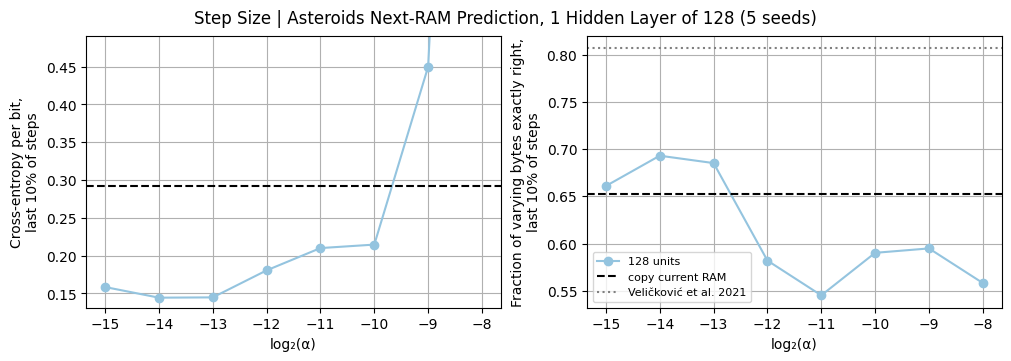

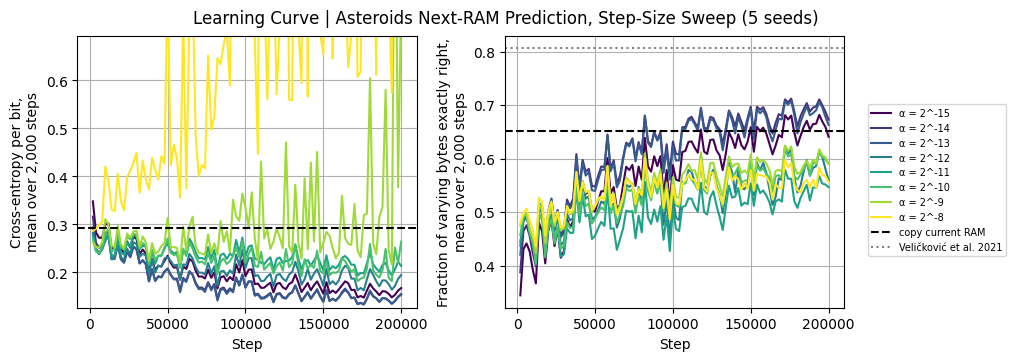

In [37]:
curves = sweep(x, a, y, width=512, depth=1, n_seeds=5).mean(0)
plot_sweep({'128 units': np.asarray(curves)}, 'Step Size | Asteroids Next-RAM Prediction, 1 Hidden Layer of 128 (5 seeds)')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
steps = WINDOW * np.arange(1, curves.shape[-1] + 1)  # end of each window
for metrics, color, step_size in zip(np.asarray(curves), plt.cm.viridis(np.linspace(0, 1, len(STEP_SIZES))), STEP_SIZES):
    for ax, values in zip(axes, metrics):
        ax.plot(steps, values, color=color, label=f'α = 2^{np.log2(step_size):.0f}')
for ax, ref, name in zip(axes, copy_final, ['Cross-entropy per bit', 'Fraction of varying bytes exactly right']):
    ax.axhline(ref, color='k', ls='--', label='copy current RAM')
    ax.set(xlabel='Step', ylabel=f'{name},\nmean over {WINDOW:,} steps')
    ax.grid()
axes[1].axhline(RMR_ACCURACY, color='gray', ls=':', label='Veličković et al. 2021')
# Losses above ln 2 are worse than predicting 0.5 for every bit and are cut off.
axes[0].set_ylim(0.95 * min(np.nanmin(curves[:, 0]), copy_final[0]), np.log(2))
fig.legend(*axes[1].get_legend_handles_labels(), fontsize=7, loc='outside right center')
fig.suptitle('Learning Curve | Asteroids Next-RAM Prediction, Step-Size Sweep (5 seeds)')

## 2. Width

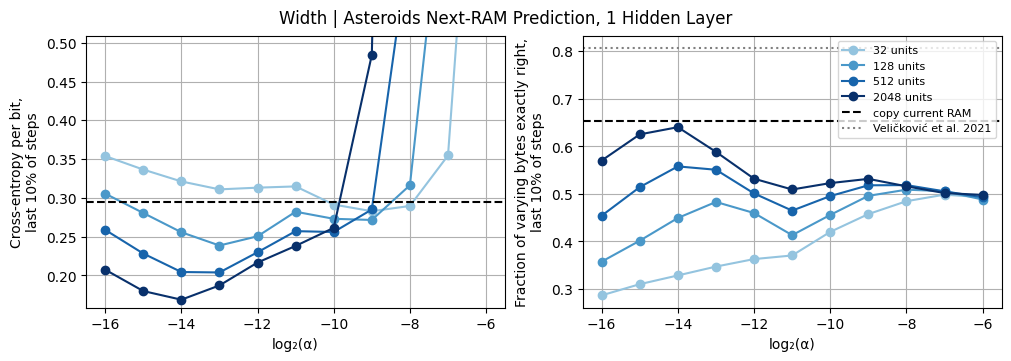

In [9]:
plot_sweep({f'{w} units': np.asarray(sweep(x, a, y, width=w, depth=1, n_seeds=1)[0]) for w in (32, 128, 512)},
           'Width | Asteroids Next-RAM Prediction, 1 Hidden Layer')

## 3. Depth

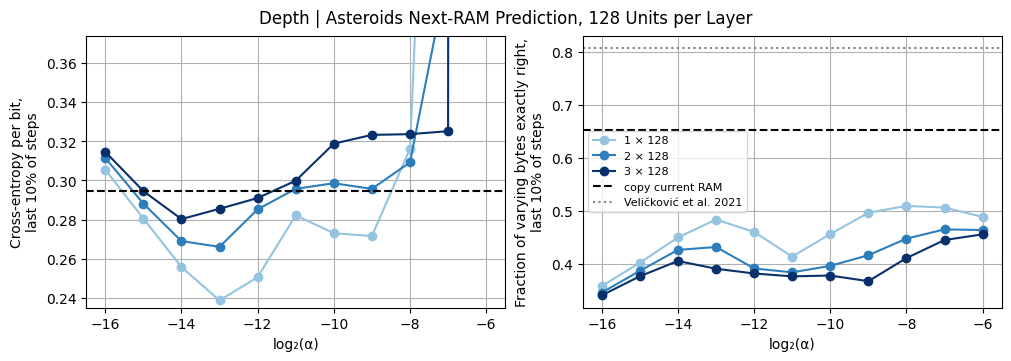

In [10]:
plot_sweep({f'{d} × 128': np.asarray(sweep(x, a, y, width=128, depth=d, n_seeds=1)[0]) for d in (1, 2, 3)},
           'Depth | Asteroids Next-RAM Prediction, 128 Units per Layer')